Figure 3


Imports

In [56]:
#imports
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import os, glob, time, itertools
import matplotlib.pyplot as plt
from matplotlib import colors, cm
from matplotlib.lines import Line2D
# !pip install -U torch

new adamw optimizer (remember to run)

In [57]:
# @title
# copied from source code

import math
import torch
from torch.optim.optimizer import Optimizer


class AdamW(Optimizer):
    def __init__(
        self,
        params,
        lr=1e-3,
        betas=(0.9, 0.999),
        eps=1e-8,
        weight_decay=1e-2,
        amsgrad=False,
    ):
        """
        AdamW implementation with logistic weight decay

        Args:
            params (iterable): Iterable of parameters to optimize
            lr (float, optional): Learning rate (default: 1e-3)
            betas (tuple[float, float], optional): Coefficients for computing running averages of gradient and its square (default: (0.9, 0.999))
            eps (float, optional): Term added to denominator to improve numerical stability (default: 1e-8)
            weight_decay (float, optional): Weight decay coefficient (default: 1e-2)
            amsgrad (bool, optional): Whether to use the AMSGrad variant (default: False)
        """
        if not 0.0 <= lr:
            raise ValueError(f"Invalid learning rate: {lr}")
        if not 0.0 <= eps:
            raise ValueError(f"Invalid epsilon value: {eps}")
        if not 0.0 <= betas[0] < 1.0:
            raise ValueError(f"Invalid beta parameter at index 0: {betas[0]}")
        if not 0.0 <= betas[1] < 1.0:
            raise ValueError(f"Invalid beta parameter at index 1: {betas[1]}")
        #if not 0.0 <= weight_decay:
            #raise ValueError(f"Invalid weight_decay value: {weight_decay}")

        defaults = dict(
            lr=lr,
            betas=betas,
            eps=eps,
            weight_decay=weight_decay,
            amsgrad=amsgrad
        )
        super().__init__(params, defaults)

    def __setstate__(self, state):
        super().__setstate__(state)
        for group in self.param_groups:
            group.setdefault('amsgrad', False)

    @torch.no_grad()
    def step(self, closure=None):
        """
        Performs a single optimization step.

        Args:
            closure (callable, optional): A closure that reevaluates the model and returns the loss
        """
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            params_with_grad = []
            grads = []
            exp_avgs = []
            exp_avg_sqs = []
            max_exp_avg_sqs = []
            state_steps = []
            beta1, beta2 = group['betas']

            for p in group['params']:
                if p.grad is None:
                    continue
                params_with_grad.append(p)
                if p.grad.is_sparse:
                    raise RuntimeError('AdamW does not support sparse gradients')
                grads.append(p.grad)

                state = self.state[p]

                # State initialization
                if len(state) == 0:
                    state['step'] = 0
                    # Exponential moving average of gradient values
                    state['exp_avg'] = torch.zeros_like(p, memory_format=torch.preserve_format)
                    # Exponential moving average of squared gradient values
                    state['exp_avg_sq'] = torch.zeros_like(p, memory_format=torch.preserve_format)
                    if group['amsgrad']:
                        # Maintains max of all exp. moving avg. of sq. grad. values
                        state['max_exp_avg_sq'] = torch.zeros_like(p, memory_format=torch.preserve_format)

                exp_avgs.append(state['exp_avg'])
                exp_avg_sqs.append(state['exp_avg_sq'])

                if group['amsgrad']:
                    max_exp_avg_sqs.append(state['max_exp_avg_sq'])

                state['step'] += 1
                state_steps.append(state['step'])

            # Perform stepweight decay
            for p in params_with_grad:
                if group['weight_decay'] >= 0:
                    p.mul_(1 - group['weight_decay'] * group['lr'])
                else:
                    row_norms = p.norm(dim=1).unsqueeze(1).add_(group['eps'])
                    decay_factor = group['weight_decay'] * p * (1 - 1/row_norms)
                    p.add_(decay_factor, alpha=group['lr'])

            # Update momentum and variance
            for i, param in enumerate(params_with_grad):
                grad = grads[i]
                exp_avg = exp_avgs[i]
                exp_avg_sq = exp_avg_sqs[i]
                step = state_steps[i]

                bias_correction1 = 1 - beta1 ** step
                bias_correction2 = 1 - beta2 ** step

                # Update biased first moment estimate
                exp_avg.mul_(beta1).add_(grad, alpha=1 - beta1)
                # Update biased second raw moment estimate
                exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                if group['amsgrad']:
                    max_exp_avg_sq = max_exp_avg_sqs[i]
                    # Maintains the maximum of all 2nd moment running avg. till now
                    torch.maximum(max_exp_avg_sq, exp_avg_sq, out=max_exp_avg_sq)
                    # Use the max. for normalizing running avg. of gradient
                    denom = (max_exp_avg_sq.sqrt() / math.sqrt(bias_correction2)).add_(group['eps'])
                else:
                    denom = (exp_avg_sq.sqrt() / math.sqrt(bias_correction2)).add_(group['eps'])

                step_size = group['lr'] / bias_correction1
                param.addcdiv_(exp_avg, denom, value=-step_size)

        return loss

data sampler


In [58]:
# data sampler

# power-law probability distribution
def feature_probs(n, alpha, E = 1.0, device = None):
  i = torch.arange(1, n+1, dtype=torch.float32, device=device)
  p = i ** (-alpha)
  return E * p / p.sum()

# samples a batch with bernoulli drawing
def sampler(p, batch_size = 2048):
  u = p.expand(batch_size, -1)
  u = torch.bernoulli(u)
  v = torch.rand([batch_size, p.numel()], device = p.device)*2
  x = u * v
  return x


In [59]:
# @title
# test functions
x = feature_probs(100, alpha = 1)
print(x)
print(sampler(x))
print(sampler(x).shape)


p = feature_probs(1000, 1.0)
print(p[0])
print((sampler(p) > 0).float().sum(dim=1).mean())

tensor([0.1928, 0.0964, 0.0643, 0.0482, 0.0386, 0.0321, 0.0275, 0.0241, 0.0214,
        0.0193, 0.0175, 0.0161, 0.0148, 0.0138, 0.0129, 0.0120, 0.0113, 0.0107,
        0.0101, 0.0096, 0.0092, 0.0088, 0.0084, 0.0080, 0.0077, 0.0074, 0.0071,
        0.0069, 0.0066, 0.0064, 0.0062, 0.0060, 0.0058, 0.0057, 0.0055, 0.0054,
        0.0052, 0.0051, 0.0049, 0.0048, 0.0047, 0.0046, 0.0045, 0.0044, 0.0043,
        0.0042, 0.0041, 0.0040, 0.0039, 0.0039, 0.0038, 0.0037, 0.0036, 0.0036,
        0.0035, 0.0034, 0.0034, 0.0033, 0.0033, 0.0032, 0.0032, 0.0031, 0.0031,
        0.0030, 0.0030, 0.0029, 0.0029, 0.0028, 0.0028, 0.0028, 0.0027, 0.0027,
        0.0026, 0.0026, 0.0026, 0.0025, 0.0025, 0.0025, 0.0024, 0.0024, 0.0024,
        0.0024, 0.0023, 0.0023, 0.0023, 0.0022, 0.0022, 0.0022, 0.0022, 0.0021,
        0.0021, 0.0021, 0.0021, 0.0021, 0.0020, 0.0020, 0.0020, 0.0020, 0.0019,
        0.0019])
tensor([[0.0000, 0.4197, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
        [1.2578, 0.0000, 0.0000,  ..., 

Toy Model

In [60]:
class ToyModel(nn.Module):
  def __init__(self, n, m):
    super().__init__()
    self.W = nn.Parameter(torch.randn(n, m) / math.sqrt(m))
    self.b = nn.Parameter(torch.randn(n))


  def forward(self, x):
    h = x @ self.W
    y = torch.relu(h @ self.W.T + self.b)
    return y

In [61]:
# @title
# test cases

model = ToyModel(1000, 100)
x = sampler(p)
model.W.norm(dim=1)[:5] # your init norms
model(x).shape # expect [2048, 1000]
sum(q.numel() for q in model.parameters())


101000

Learning Rate Scheduler

In [62]:
# Learning rate: base_lr =  0.02, scaled according to hidden dimension
# warmup (5% of total steps) and cosine decay learning schedule rate
# learning rate (from exp-17)

# from text

def lr_multiplier(step, n_steps, warmup_ratio = 0.05):
  warmup_steps = int(warmup_ratio*n_steps)
  step += 1
  min_lr = 0.05 # test this?
  if step < warmup_steps:
    return step/warmup_steps
  else:
    # taken from paper text
    return (1.0 - min_lr) * 0.5 * (1 + math.cos(math.pi * (step - warmup_steps) / (n_steps - warmup_steps))) + min_lr

In [63]:
n = 1000
m_values = [10, 15, 25, 39, 63, 100]
batch_size = 2048
steps = 20000
gamma_values = np.linspace(-1, 1, 10)
alpha_values = np.linspace(0, 2, 17)
base_lr = 0.01

'''
Learning rate: Initialized at 1 ×10−2, dynamically adjusted using cosine decay scheduling
with a warm-up phase of 2000 steps.
'''

'\nLearning rate: Initialized at 1 ×10−2, dynamically adjusted using cosine decay scheduling\nwith a warm-up phase of 2000 steps.\n'

training loop

In [64]:

def training_loop(n, m, alpha, batch_size, n_steps, warmup_ratio, gamma, base_lr = 1e-2, E= 1.0, seed = 0, device = "cuda"):
    torch.manual_seed(seed)
    p = feature_probs(n, alpha, E, device)
    model = ToyModel(n, m).to(device)


    optimizer = AdamW([
          {"params": [model.W], "lr": base_lr, "weight_decay": gamma},
          {"params": [model.b], "lr": base_lr, "weight_decay": 0.0},
      ])

    print(optimizer.param_groups[0]["weight_decay"])

    for g in optimizer.param_groups:
      g['init_lr'] = g['lr']

    losses = torch.empty(n_steps, device = device)

    for step in range(n_steps):
      x = sampler(p, batch_size) # b x n
      y = model(x) # b x n
      loss = ((y-x)**2).mean()

      optimizer.zero_grad()
      loss.backward()
      losses[step] = loss.detach()

      for g in optimizer.param_groups:
        g['lr'] = g['init_lr'] * lr_multiplier(step, n_steps, warmup_ratio)

      optimizer.step()

    with torch.no_grad():
        test_loss = sum(
            ((model(xt) - xt) ** 2).sum(dim=1).mean().item()
            for xt in (sampler(p, batch_size) for _ in range(100))
        ) / 100

    return {
        "W": model.W.detach().cpu(),
        "b": model.b.detach().cpu(),
        "losses": losses.cpu(),
        "test_loss": test_loss,
        "cfg": dict(n=n, m=m, alpha=alpha, E=E, gamma=gamma, seed=seed,
                    batch_size=batch_size, n_steps=n_steps,
                    base_lr=base_lr, warmup_ratio=warmup_ratio),
    }




google drive mount

In [65]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [66]:
import os
os.listdir('/content/drive/MyDrive/superposition_repro')

['fig3b',
 'fig4_sweep',
 'fig3a',
 'fig4_metrics.csv',
 'a0.000_g-1.000_m10.pt',
 'fig4']

In [67]:
out_dir = '/content/drive/MyDrive/superposition_repro'

In [68]:
def cached_run(path, **cfg):
    """Load a saved run if it exists, otherwise train, save, and return it."""
    if os.path.exists(path):
        saved = torch.load(path, weights_only=False)
        assert saved['config'] == cfg, f"{path} was trained with {saved['config']}"
        print(f"loaded {path}")
        return saved['out']
    out = training_loop(**cfg)
    out = {k: v.detach().cpu() if torch.is_tensor(v) else v for k, v in out.items()}
    torch.save({'config': cfg, 'out': out}, path)
    print(f"saved {path}")
    return out

In [69]:
root = '/content/drive/MyDrive/superposition_repro'
fig3a_dir = os.path.join(root, 'fig3a')
fig3b_dir = os.path.join(root, 'fig3b')
for d in (fig3a_dir, fig3b_dir):
    os.makedirs(d, exist_ok=True)
print(fig3a_dir, fig3b_dir)

/content/drive/MyDrive/superposition_repro/fig3a /content/drive/MyDrive/superposition_repro/fig3b


In [70]:
def run_path(a, g, m):
    return f"{out_dir}/a{a:.3f}_g{g:+.3f}_m{m}.pt"

In [71]:
# figure saving

import os
FIG_DIR = "/content/drive/MyDrive/superposition_repro/figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(fig, name):
    for ext in ("png", "pdf"):
        path = f"{FIG_DIR}/{name}.{ext}"
        fig.savefig(path, dpi=200, bbox_inches="tight")
    print("saved", name)

Figure 3a


- tune weight decay (+-1)
- positive weight decay --> less superposition  (why??)
- consistent across model width


In [72]:
# %%script echo "skip 3a training cell"

n, m = 1000, 100
runs, norms = {}, {}
for gamma in [1.0, -1.0]:
    path = f"/content/drive/MyDrive/superposition_repro/fig3a/gamma{gamma:+.0f}.pt"
    runs[gamma] = cached_run(path, n=n, m=m, alpha=1, batch_size=2048,
                             n_steps=20000, warmup_ratio=0.1, gamma=gamma)
    norms[gamma] = runs[gamma]['W'].norm(dim=1).numpy()
    print(f"γ={gamma:+.0f}  φ½={(norms[gamma] > 0.5).mean():.3f}  "
          f"test loss={runs[gamma]['test_loss']:.3e}")

loaded /content/drive/MyDrive/superposition_repro/fig3a/gamma+1.pt
γ=+1  φ½=0.074  test loss=8.350e-01
loaded /content/drive/MyDrive/superposition_repro/fig3a/gamma-1.pt
γ=-1  φ½=1.000  test loss=4.438e-02


saved fig3a


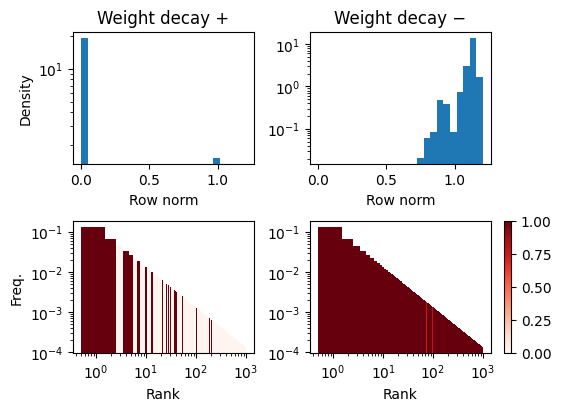

In [73]:
saved = {g: torch.load(f"/content/drive/MyDrive/superposition_repro/fig3a/gamma{g:+.0f}.pt",
                       weights_only=False)
         for g in [1.0, -1.0]}
norms = {g: s["out"]["W"].norm(dim=1).numpy() for g, s in saved.items()}
cfg = saved[1.0]["config"]
n = cfg["n"]

p = feature_probs(n, cfg["alpha"]).cpu().numpy()
rank = np.arange(1, n + 1)
bins = np.linspace(0, max(w.max() for w in norms.values()) * 1.02, 26)
reds, unit = plt.get_cmap("Reds"), colors.Normalize(0, 1)

fig, axes = plt.subplots(2, 2, figsize=(5.5, 4), constrained_layout=True)
for col, (gamma, title) in enumerate([(1.0, "Weight decay +"), (-1.0, "Weight decay −")]):
    w = norms[gamma]
    axes[0, col].hist(w, bins=bins, density=True)
    axes[0, col].set(yscale="log", xlabel="Row norm", title=title)
    axes[1, col].bar(rank, p, width=1.0, color=reds(unit(np.clip(w, 0, 1))), linewidth=0)
    axes[1, col].set(xscale="log", yscale="log", xlabel="Rank")
axes[0, 0].set_ylabel("Density")
axes[1, 0].set_ylabel("Freq.")
fig.colorbar(cm.ScalarMappable(unit, reds), ax=axes[1, 1])


save_fig(fig, "fig3a")
plt.show()

In [74]:
# out = training_loop(gamma = 1, alpha =1 , m =100, n=1000, n_steps = 20000, base_lr = 1e-2, batch_size = 2048, warmup_ratio = 0.1)

Figure 3b

In [75]:
# vary m and vary gamma

m_values = [10, 15, 25, 39, 63, 100]
gamma_values = np.linspace(-1, 1, 10)

In [76]:
%%script echo "skip 3b training cell"

import os, time
import numpy as np

os.makedirs("/content/drive/MyDrive/superposition_repro/fig3b", exist_ok=True)

n = 1000
norms_3b = np.full((len(m_values), len(gamma_values), n), np.nan, dtype=np.float32)

for i, m in enumerate(m_values):
    for j, gamma in enumerate(gamma_values):
        t0 = time.time()
        path = f"/content/drive/MyDrive/superposition_repro/fig3b/m{int(m)}_gamma{float(gamma):+.2f}.pt"
        out = cached_run(path, n=n, m=int(m), alpha=1, batch_size=2048, n_steps=20000,
                         warmup_ratio=0.1, gamma=float(gamma))
        norms_3b[i, j] = out["W"].norm(dim=1).numpy()
        print(f"m={m:3d}  γ={gamma:+.2f}  φ½={(norms_3b[i, j] > 0.5).mean():.3f}  ({time.time() - t0:.0f}s)")

skip 3b training cell


In [77]:
import os
import numpy as np
import torch

FIG3B_DIR = "/content/drive/MyDrive/superposition_repro/fig3b"
n = 1000

def ckpt_path(m, gamma):
    return f"{FIG3B_DIR}/m{int(m)}_gamma{float(gamma):+.2f}.pt"

missing = [ckpt_path(m, g) for m in m_values for g in gamma_values
           if not os.path.exists(ckpt_path(m, g))]
assert not missing, f"{len(missing)} checkpoints missing, e.g. {missing[:3]}"

norms = np.full((len(m_values), len(gamma_values), n), np.nan, dtype=np.float32)
for i, m in enumerate(m_values):
    for j, gamma in enumerate(gamma_values):
        ckpt = torch.load(ckpt_path(m, gamma), map_location="cpu", weights_only=False)
        cfg, W = ckpt["config"], ckpt["out"]["W"]
        assert W.shape == (n, m), (m, gamma, tuple(W.shape))
        assert cfg["n"] == n and cfg["m"] == m and cfg["alpha"] == 1, (m, gamma, cfg)
        assert abs(cfg["gamma"] - gamma) < 1e-6, (m, gamma, cfg["gamma"])
        norms[i, j] = W.norm(dim=1).numpy()

np.savez(f"{FIG3B_DIR}/fig3b_norms.npz", norms=norms,
         m_values=np.array(m_values), gamma_values=gamma_values, n=n, alpha=1.0)
print("saved", norms.shape)

saved (6, 10, 1000)


saved fig3b


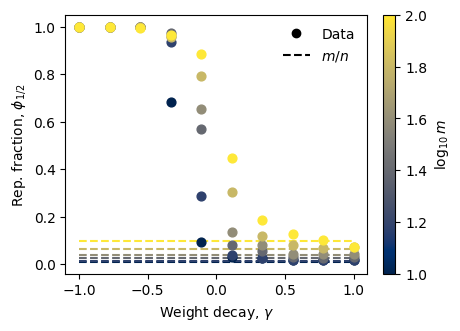

In [78]:
# %%script echo "skip plot 3b cell"

d = np.load("/content/drive/MyDrive/superposition_repro/fig3b/fig3b_norms.npz")
norms_3b, m_vals, gammas, n = d["norms"], d["m_values"], d["gamma_values"], int(d["n"])
assert norms_3b.shape == (len(m_vals), len(gammas), n), norms_3b.shape
assert not np.isnan(norms_3b).any(), "some runs are missing (NaN entries)"

phi = (norms_3b > 0.5).mean(axis=-1)   # (len(m_vals), len(gammas))
civ, lognorm = plt.get_cmap("cividis"), colors.Normalize(1, 2)

fig, ax = plt.subplots(figsize=(4.5, 3.2), constrained_layout=True)
for i, m in enumerate(m_vals):
    c = civ(lognorm(np.log10(m)))
    ax.hlines(m / n, gammas[0], gammas[-1], colors=[c], linestyles="--")
    ax.scatter(gammas, phi[i], color=c, s=40, zorder=3)
ax.set(xlabel=r"Weight decay, $\gamma$", ylabel=r"Rep. fraction, $\phi_{1/2}$")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="k", label="Data"),
                   Line2D([], [], ls="--", color="k", label=r"$m/n$")], frameon=False)
fig.colorbar(cm.ScalarMappable(lognorm, civ), ax=ax, label=r"$\log_{10} m$")

save_fig(fig, "fig3b")
plt.show()

In [79]:
# m = 0 # model_dimension
# W_lr = base_lr * (8.0 / m) ** 0.25   # scaled base lr
# b_lr = 2.0 / m


# weight_decay = {}

# ## optimizer
# optimizer = AdamW()

# '''
#  Specifically, for weight matrix W, learning rate was scaled as
# lr ×(8/m)0.25 with specified weight decay
# '''

# '''
#  And for bias vector b, a learning rate of 2.0/mwas used
# with no weight decay. A cosine decay learning rate schedule with a warm-up phase (5% of total
# steps) was implemented.
# '''


# """
# he final test loss is calculated across newly sampled data
# with a size being 100 times the batch size.
# """

figure 4:

- number of represented features x alpha value --> loss
-



components:
- padded upper left corner reference matrix  --> compute norm difference
ambiguity tensor



In [80]:
# vary m and vary gamma

m_values = [10, 15, 25, 39, 63, 100]
gamma_values = np.linspace(-1, 1, 10)
alphas = np.linspace(0, 2, 17)

In [81]:
from google.colab import drive
import glob, torch
drive.mount('/content/drive')

out_dir = '/content/drive/MyDrive/superposition_repro/fig4_sweep'
runs = [torch.load(f, weights_only=False) for f in sorted(glob.glob(f"{out_dir}/*.pt"))]
print(len(runs), "runs loaded")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1020 runs loaded


In [82]:
# %%script echo "train and load figure 4 runs$

configs = list(itertools.product(alphas, gamma_values, m_values))
t0 = time.time()
for i, (a, g, m) in enumerate(configs, 1):
    path = run_path(a, g, m)
    if os.path.exists(path):
        continue                                          # finished in an earlier session
    r = training_loop(1000, m, float(a), 2048, 20000, 0.1, float(g))
    r["k"] = (r["W"].norm(dim=1) > 0.5).sum().item()
    r = {key: (v.cpu() if torch.is_tensor(v) else v) for key, v in r.items()}  # loadable without a GPU
    torch.save(r, path + ".tmp")
    os.replace(path + ".tmp", path)                       # rename only after a complete write
    print(f"[{i}/{len(configs)}] a={a:.3f} g={g:+.3f} m={m}  "
          f"k={r['k']}  loss={r['test_loss']:.4f}  ({time.time() - t0:.0f}s)")

n_saved = sum(os.path.exists(run_path(*c)) for c in configs)
print(f"done: {n_saved}/{len(configs)} runs saved")


done: 1020/1020 runs saved


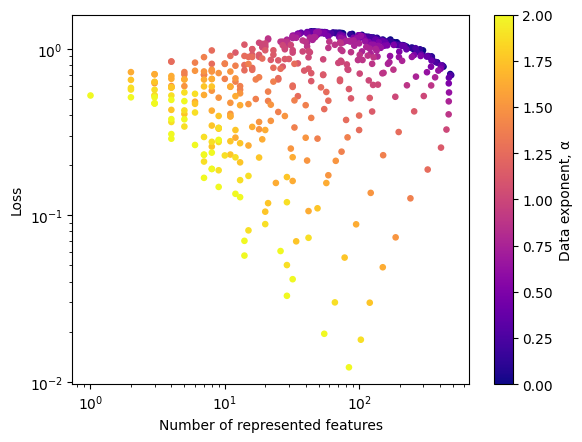

In [83]:
import matplotlib.pyplot as plt

pos = [r for r in runs if r["cfg"]["gamma"] > 0]      # weak-superposition runs, as in Fig. 4a
k = [r["k"] for r in pos]
loss = [r["test_loss"] for r in pos]
alpha = [r["cfg"]["alpha"] for r in pos]

plt.scatter(k, loss, c=alpha, cmap="plasma", vmin=0, vmax=2, s=14)
plt.colorbar(label="Data exponent, α")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Number of represented features"); plt.ylabel("Loss")
plt.show()

In [84]:
def theory_loss(k, alpha, n=1000):
    phi = k / n
    if alpha == 1:
        return (4/3) * -np.log(phi) / np.log(n)
    return (4/3) * (phi**(1 - alpha) - 1) / (1 - n**(1 - alpha)) * n**(1 - alpha)


saved fig4a


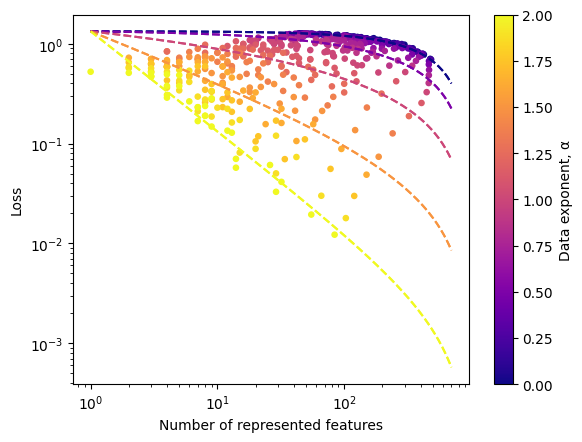

In [85]:

ks = np.logspace(0, np.log10(700), 200)
for a in [0, 0.5, 1, 1.5, 2]:
    plt.plot(ks, theory_loss(ks, a), "--", color=plt.cm.plasma(a / 2))

plt.xscale("log"); plt.yscale("log")
plt.xlabel("Number of represented features"); plt.ylabel("Loss")

plt.scatter(k, loss, c=alpha, cmap="plasma", vmin=0, vmax=2, s=14)
plt.colorbar(label="Data exponent, α")

ks = np.logspace(0, np.log10(700), 200)
for a in [0, 0.5, 1, 1.5, 2]:
    plt.plot(ks, theory_loss(ks, a), "--", color=plt.cm.plasma(a / 2))

plt.xscale("log"); plt.yscale("log")
plt.xlabel("Number of represented features"); plt.ylabel("Loss")
save_fig(fig, "fig4a")
plt.show()

figure 4b

In [86]:
from google.colab import drive
import glob, torch
drive.mount('/content/drive')

out_dir = '/content/drive/MyDrive/superposition_repro/fig4_sweep'
runs = [torch.load(f, weights_only=False) for f in sorted(glob.glob(f"{out_dir}/*.pt"))]
print(len(runs), "runs loaded")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1020 runs loaded


In [87]:
r = runs[0]
print(type(r))
print(r.keys())
print(r['cfg'])
print(r['W'])

<class 'dict'>
dict_keys(['W', 'b', 'losses', 'test_loss', 'cfg', 'k'])
{'n': 1000, 'm': 10, 'alpha': 0.0, 'E': 1.0, 'gamma': 0.11111111111111116, 'seed': 0, 'batch_size': 2048, 'n_steps': 20000, 'base_lr': 0.01, 'warmup_ratio': 0.1}
tensor([[-3.2698e-02,  4.7447e-03, -1.5091e-02,  ..., -1.5637e-03,
          7.4600e-03,  1.7215e-02],
        [ 1.4737e-02, -1.7759e-02, -8.3032e-03,  ...,  1.6003e-02,
          1.4054e-02, -3.5041e-03],
        [ 8.7864e-03, -2.5567e-02,  3.3352e-02,  ..., -1.3708e-02,
         -4.0531e-03, -1.2782e-02],
        ...,
        [-6.4212e-03,  9.3866e-03,  2.8521e-03,  ..., -2.5619e-02,
         -1.3795e-02, -9.6171e-05],
        [ 7.6719e-04,  5.2779e-03,  3.4816e-02,  ..., -1.7744e-02,
          1.0012e-02, -1.4611e-02],
        [-3.0399e-02, -1.2162e-03,  2.3894e-02,  ...,  9.2498e-03,
          5.1204e-03,  1.3250e-02]])


In [88]:
m_values = [10, 15, 25, 39, 63, 100]
gamma_values = np.linspace(-1, 1, 10)
alphas = np.linspace(0, 2, 17)

In [89]:
# @title
# inverse helper functions
M_IDX = {m: i for i, m in enumerate(m_values)}

def m_to_idx(m):
    return M_IDX[int(m)]

def linspace_inverse(grid, atol=1e-6):
    start, step, num = grid[0], grid[1] - grid[0], len(grid)
    def to_idx(value):
        i = int(round((value - start) / step))
        if not (0 <= i < num) or abs(grid[i] - value) > atol:
            raise ValueError(f"{value} is not on the grid")
        return i
    return to_idx

gamma_to_idx = linspace_inverse(gamma_values)
alpha_to_idx = linspace_inverse(alphas)

In [90]:
def ambiguity_norm(m, n, W):
  reference = torch.zeros([n, n])
  reference[:m , :m] = torch.eye(m)
  return torch.linalg.matrix_norm(W @ W.T - reference, ord = "fro")

ambiguity = torch.full([len(m_values), len(gamma_values), len(alphas)], float("nan"))

for r in runs:
  m, gamma, alpha = r['cfg']['m'], r['cfg']['gamma'], r['cfg']['alpha']
  m_i = m_to_idx(m)
  g_i = gamma_to_idx(gamma)
  a_i = alpha_to_idx(alpha)
  n = r['cfg']['n']
  w = r["W"]
  ambiguity[m_i, g_i, a_i] = ambiguity_norm(m,n,w)


In [91]:
worst = ambiguity.flatten(1, 2).max(dim = 0).values
print(worst)
print(worst.shape)

tensor([472.5562, 467.5074, 478.5165, 488.5681, 479.1436, 478.9971, 455.3287,
        443.3321, 431.0922, 431.7707, 418.7104, 402.1544, 382.1095, 391.2145,
        358.9306, 352.3268, 347.9451, 451.5796, 450.3667, 461.7019, 467.8166,
        457.7292, 459.8254, 439.0004, 433.2664, 424.0280, 422.7519, 414.1563,
        390.8702, 377.3312, 368.6736, 351.6562, 337.4142, 337.2775, 412.7659,
        417.0769, 427.0031, 428.8251, 423.5629, 425.8292, 407.7476, 391.7940,
        398.9842, 388.8417, 380.9601, 376.2799, 369.3030, 354.4983, 344.9903,
        323.1675, 317.4078, 337.4503, 334.1574, 341.6755, 339.8010, 324.9190,
        314.8885, 301.0674, 288.6945, 311.6992, 313.1943, 318.4676, 304.0771,
        338.2012, 337.8683, 321.8745, 306.3229, 282.3784, 202.1203, 200.4679,
        197.0903, 192.1265, 182.8578, 178.3058, 183.7684, 190.1471, 197.7467,
        205.3764, 219.5323, 226.2176, 238.6561, 226.7668, 213.4773, 196.8256,
        192.7883,  88.9025,  83.6738,  76.4495,  63.9396,  64.18

In [92]:
points = torch.topk(worst, k=9, largest = False)
print(points.indices)

tensor([101, 115, 116, 100, 117, 118, 133, 114, 134])


In [93]:
points.values

tensor([6.7653, 8.2134, 8.3886, 8.4804, 8.4991, 8.7600, 8.9089, 8.9355, 9.0339])

In [94]:
g_i, alpha_i = np.unravel_index(points.indices.numpy(), ambiguity.shape[1:])

In [95]:
from scipy.stats import linregress

case_alpha = alphas[alpha_i]
case_gamma = gamma_values[g_i]


losses = []
for id in range(9):
  curr_losses = []
  alpha, gamma = case_alpha[id], case_gamma[id]
  for m in m_values:
    ckpt = torch.load(run_path(alpha, gamma, m), weights_only=False)
    curr_losses.append(ckpt["test_loss"])
  losses.append(curr_losses)


fits = [linregress(np.log(m_values), np.log(losses[c])) for c in range(9)]
alpha_m = np.array([-f.slope for f in fits])
alpha_m_error = np.array([f.stderr for f in fits])


for c in range(9):
    print(f"α={case_alpha[c]:.3f}  γ={case_gamma[c]:+.2f}  α_m={alpha_m[c]:.2f} ± {alpha_m_error[c]:.2f}")




α=2.000  γ=+0.11  α_m=1.35 ± 0.07
α=1.625  γ=+0.33  α_m=0.87 ± 0.06
α=1.750  γ=+0.33  α_m=0.91 ± 0.14
α=1.875  γ=+0.11  α_m=1.25 ± 0.08
α=1.875  γ=+0.33  α_m=0.95 ± 0.13
α=2.000  γ=+0.33  α_m=1.08 ± 0.16
α=1.750  γ=+0.56  α_m=0.69 ± 0.10
α=1.500  γ=+0.33  α_m=0.66 ± 0.04
α=1.875  γ=+0.56  α_m=0.76 ± 0.11


saved fig4b


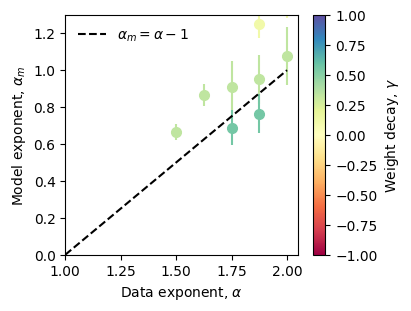

In [96]:
import matplotlib.pyplot as plt
from matplotlib import colors, cm

cmap, norm = plt.get_cmap("Spectral"), colors.Normalize(-1, 1)

fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)
for c in range(9):
    ax.errorbar(case_alpha[c], alpha_m[c], yerr=alpha_m_error[c], fmt="o",
                color=cmap(norm(case_gamma[c])), ms=7)
ax.plot([1, 2], [0, 1], "k--", label=r"$\alpha_m = \alpha - 1$")
ax.set(xlabel=r"Data exponent, $\alpha$", ylabel=r"Model exponent, $\alpha_m$",
       xlim=(1, 2.05), ylim=(0, 1.3))
ax.legend(frameon=False)
fig.colorbar(cm.ScalarMappable(norm, cmap), ax=ax, label=r"Weight decay, $\gamma$")

save_fig(fig, "fig4b")
plt.show()

In [97]:
import os
import numpy as np

path = "/content/drive/MyDrive/superposition_repro/fig4/fig4_frobenius.npz"
os.makedirs(os.path.dirname(path), exist_ok=True)

np.savez(
    path,
    ambiguity=ambiguity.numpy(),          # (6, 10, 17): m × γ × α
    m_values=np.array(m_values),
    gamma_values=gamma_values,
    alphas=alphas,
    g_i=g_i, alpha_i=alpha_i,             # the 9 picks, as grid positions
    worst=points.values.numpy(),          # their worst-case ambiguity
    alpha_m=alpha_m, alpha_m_error=alpha_m_error,
    norm="fro",                           # records which norm produced this
)

In [98]:
d = np.load(path)
print(d.files)                                   # every name you saved
print(np.allclose(d["ambiguity"], ambiguity.numpy()))   # should print True
print(d["gamma_values"][d["g_i"]])               # γ of your 9 picks

['ambiguity', 'm_values', 'gamma_values', 'alphas', 'g_i', 'alpha_i', 'worst', 'alpha_m', 'alpha_m_error', 'norm']
True
[0.11111111 0.33333333 0.33333333 0.11111111 0.33333333 0.33333333
 0.55555556 0.33333333 0.55555556]


notes:

- uses frobenius norm
  - why is this super necessary???

- understand why the ambiguity rank is useful here


- noticed many dead features 2-7 in debugging session?
 - is this a typical result of the existing experiments?


random tests

In [99]:
# @title
# test whether weight decay is the same??

def test_adamw_matches():
    torch.manual_seed(0)
    W0 = torch.randn(64, 8)
    g = torch.randn(64, 8)

    # γ >= 0: must match torch.optim.AdamW exactly
    a, b = W0.clone().requires_grad_(), W0.clone().requires_grad_()
    a.grad, b.grad = g.clone(), g.clone()
    AdamW([a], lr=0.02, weight_decay=0.1).step()
    torch.optim.AdamW([b], lr=0.02, weight_decay=0.1).step()
    assert torch.allclose(a, b, atol=1e-6)

    # γ < 0 with zero grad: only Eq. 2 acts
    c = W0.clone().requires_grad_()
    c.grad = torch.zeros_like(c)
    AdamW([c], lr=0.02, weight_decay=-1.0).step()
    n = W0.norm(dim=1, keepdim=True)
    expected = W0 - 0.02 * (-1.0) * W0 * (1 / n - 1)
    assert torch.allclose(c, expected, atol=1e-6)

print(test_adamw_matches())

None
